In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.pyplot import figure
import scipy
import statsmodels as sm
plt.rcParams["figure.figsize"] = (21,4)

ModuleNotFoundError: No module named 'statsmodels'

## First we load the data and look at basic statistical properties including plotting

In [3]:
df = pd.read_csv("monthly-processed.csv")

In [5]:
df['Date'] = pd.to_datetime(df["Date"])

In [36]:
df.describe()

,Date,Price,Year,YTD_Change
count,2326,2326.000000,2326.000000,2326.000000
mean,1929-11-15 20:49:19.243337,246.605150,1929.417025,0.011964
min,1833-01-01 00:00:00,17.060000,1833.000000,-0.269139
25%,1881-06-08 12:00:00,18.940000,1881.000000,0.000000
50%,1929-11-16 00:00:00,20.680000,1929.000000,0.000000
75%,1978-04-23 12:00:00,184.000000,1978.000000,0.000000
max,2026-10-01 00:00:00,5020.000000,2026.000000,1.004405
std,NaN,563.964832,55.966770,0.082934


In [37]:
def plot_time_series(df,title='Gold price since 1833',interval=12):
    ax = plt.gca()
    freq =f"{interval}YS"
    df.plot(x='Date', y='Price',ax=ax,title=title,x_compat=True)
    ax.set_xlim(df['Date'].min(), df['Date'].max())
    ax.xaxis.set_major_locator(mdates.YearLocator(base=interval, month=1, day=1))
    ax.set_xticks(pd.date_range(start=df['Date'].min(), end=df['Date'].max(), freq=freq))
    ax.legend(['Gold Price'],loc='upper left')
    plt.show()

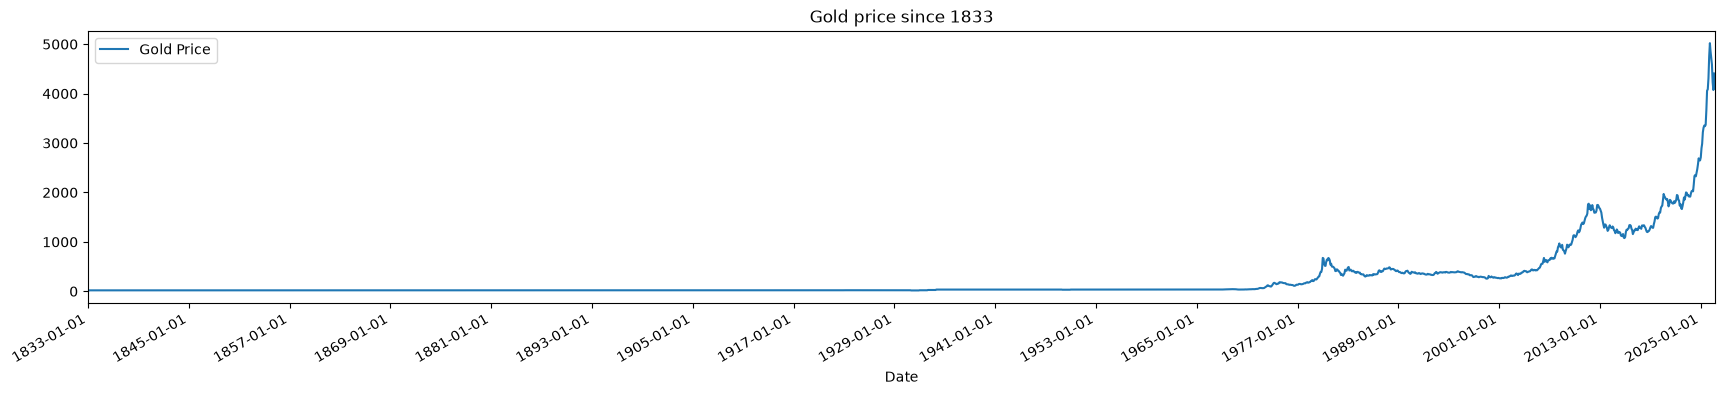

In [35]:
plot_time_series(df)

In [38]:
def plot_cumm_changes(df,title='Cumulative change in the gold price per year',start='1830-01-01',interval=10):
    df['Year'] = df['Date'].dt.year
    df['YTD_Change'] = df.groupby('Year')['Price'].transform(lambda x: (x - x.iloc[0]) / x.iloc[0])
    ax = plt.gca()
    ax.plot(df['Date'], df['YTD_Change'] * 100)
    ax.set_xlim(left=pd.Timestamp(start))
    ax.xaxis.set_major_locator(mdates.YearLocator(base=interval, month=1, day=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_ylabel('Cumulative % Change')
    ax.set_title( title)
    plt.show()
    

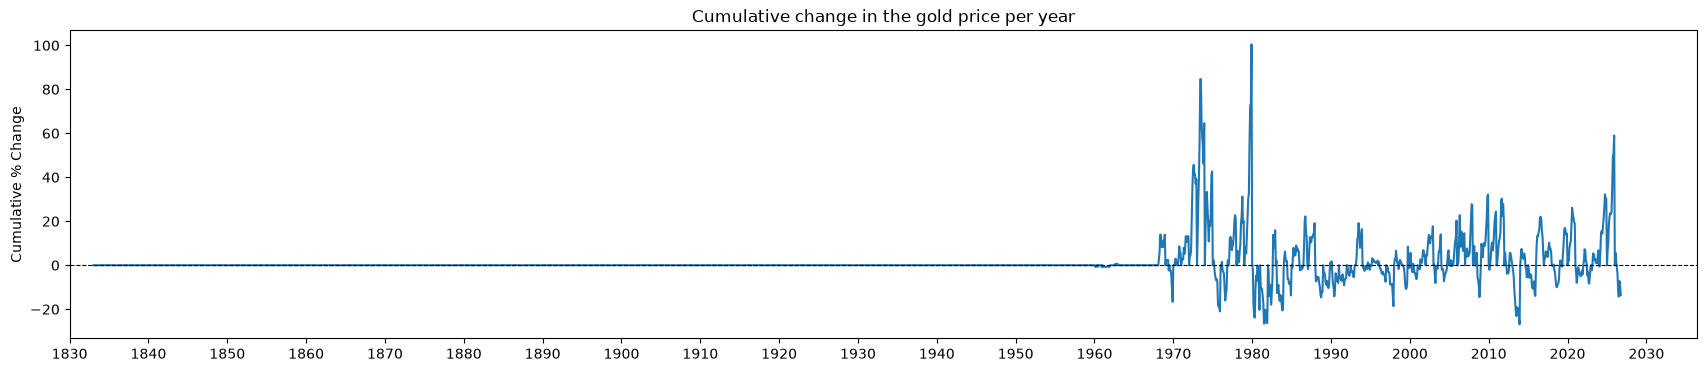

In [40]:
plot_cumm_changes(df)

We see, that there  are bearly any changes until 1970, which copies the previous data

For our analysis, we are going to use only data from last 25 years so the prediction is meaningful

In [43]:
df_analysis = df[df['Year'] > 2000]

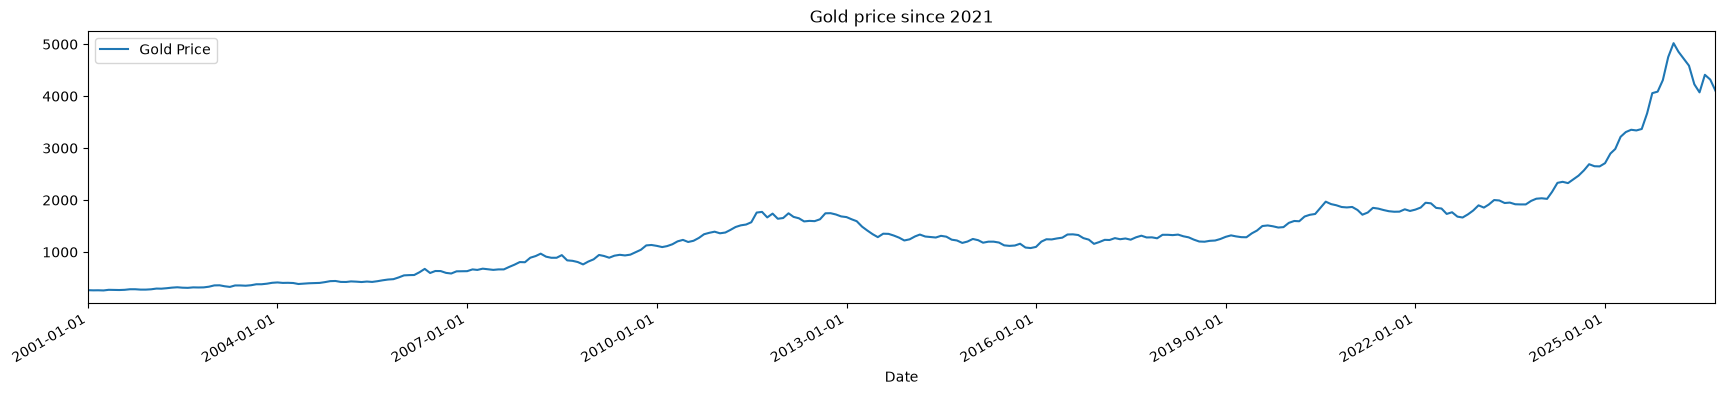

In [44]:
plot_time_series(df_analysis,title='Gold price since 2021', interval=3)

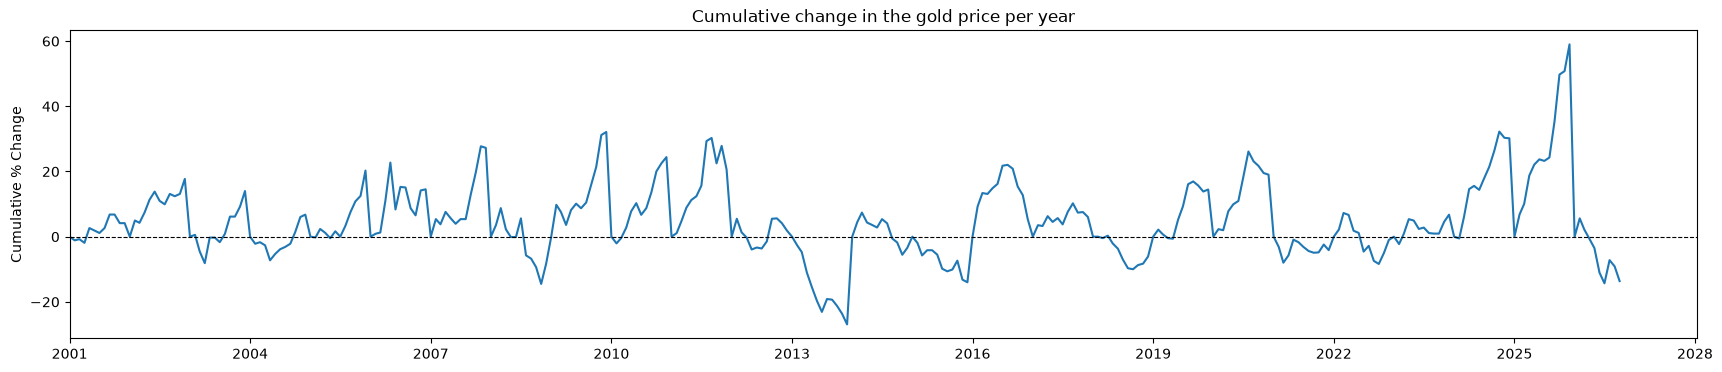

In [47]:
plot_cumm_changes(df_analysis, start='2001-01-01',interval=3)

In [66]:
def ffbs(y, s2_eps, s2_level, s2_slope, a0, P0, rng):

    n = len(y)
    T = np.array([[1.0, 1.0],      
                  [0.0, 1.0]])     
    Q = np.diag([s2_level, s2_slope])
    a_pred = np.zeros((n, 2))
    P_pred = np.zeros((n, 2, 2))
    a_filt = np.zeros((n, 2)) 
    P_filt = np.zeros((n, 2, 2))
 
    a, P = a0.copy(), P0.copy() 
    for t in range(n):
        a_pred[t], P_pred[t] = a, P
 
        v = y[t] - a[0]         
        F = P[0, 0] + s2_eps    
        K = P[:, 0] / F         
 
        a_filt[t] = a + K * v   
        P_filt[t] = P - np.outer(K, P[0, :]) 
        P_filt[t] = 0.5 * (P_filt[t] + P_filt[t].T)
 
        a = T @ a_filt[t] 
        P = T @ P_filt[t] @ T.T + Q 
    alpha = np.zeros((n, 2))
    jitter = 1e-12 * np.eye(2)
 
    alpha[-1] = a_filt[-1] + np.linalg.cholesky(P_filt[-1] + jitter) @ rng.standard_normal(2)
 
    for t in range(n - 2, -1, -1):
        J = P_filt[t] @ T.T @ np.linalg.inv(P_pred[t + 1])
        mean = a_filt[t] + J @ (alpha[t + 1] - T @ a_filt[t])
        cov = P_filt[t] - J @ T @ P_filt[t]
        cov = 0.5 * (cov + cov.T)
        alpha[t] = mean + np.linalg.cholesky(cov + jitter) @ rng.standard_normal(2)
 
    return alpha
 


In [67]:
def _draw_inv_gamma(shape, scale, rng):
    return scale / rng.gamma(shape)

In [68]:
def fit_bsts_llt(df, niter=2000, burn=500, prior_df=2.0, seed=42, verbose=True):
    """Fit a local linear trend model to df["Price"] (log scale) with Gibbs sampling.
 
    Returns a dict with posterior draws (after burn-in):
        level  (keep, n)  draws of mu_t
        slope  (keep, n)  draws of delta_t
        s2     (keep, 3)  draws of [s2_eps, s2_level, s2_slope]
        dates, y          the sorted dates and the log prices used for fitting
    """
    rng = np.random.default_rng(seed)
 
    df = df.sort_values("Date").reset_index(drop=True)
    y = np.log(df["Price"].to_numpy(dtype=float))
    n = len(y)
 
    s = np.std(np.diff(y))
    guess_sd = {"eps": 0.10 * s, "level": 0.90 * s, "slope": 0.02 * s}
    a_prior = prior_df / 2.0                                    
    b_prior = {k: a_prior * sd ** 2 for k, sd in guess_sd.items()}
 

    a0 = np.array([y[0], 0.0])
    P0 = np.diag([10.0, 0.01])
 
    s2_eps = guess_sd["eps"] ** 2
    s2_level = guess_sd["level"] ** 2
    s2_slope = guess_sd["slope"] ** 2
    keep = niter - burn
    level_draws = np.zeros((keep, n))
    slope_draws = np.zeros((keep, n))
    s2_draws = np.zeros((keep, 3))

    for it in range(niter):
 

        alpha = ffbs(y, s2_eps, s2_level, s2_slope, a0, P0, rng)
        mu, delta = alpha[:, 0], alpha[:, 1]
        resid = y - mu
        s2_eps = _draw_inv_gamma(a_prior + 0.5 * n,
                                 b_prior["eps"] + 0.5 * resid @ resid, rng)
        eta = mu[1:] - mu[:-1] - delta[:-1]
        s2_level = _draw_inv_gamma(a_prior + 0.5 * (n - 1),
                                   b_prior["level"] + 0.5 * eta @ eta, rng)
        zeta = delta[1:] - delta[:-1]
        s2_slope = _draw_inv_gamma(a_prior + 0.5 * (n - 1),
                                   b_prior["slope"] + 0.5 * zeta @ zeta, rng)
        if it >= burn:
            i = it - burn
            level_draws[i] = mu
            slope_draws[i] = delta
            s2_draws[i] = (s2_eps, s2_level, s2_slope)
 
        if verbose and (it + 1) % 500 == 0:
            print(f"iteration {it + 1}/{niter}")

    return {"level": level_draws, "slope": slope_draws, "s2": s2_draws,
            "dates": df["Date"].to_numpy(), "y": y}


In [62]:
def plot_bsts_llt(fit, ci=0.95):
    """Plot the dictionary returned by fit_bsts_llt.
 
    Panel 1: observed price with the estimated level and its credible band.
    Panel 2: estimated slope (trend), as the % price change per time step.
    Panel 3: trace plots of the three noise standard deviations (convergence check).
    """
    # 1. Unpack the fit and compute the quantiles that define the credible band.
    dates = pd.to_datetime(fit["dates"])
    lo_q, hi_q = (1 - ci) / 2, 1 - (1 - ci) / 2
 
    # 2. Level: the draws are on the log scale, so exp() brings them back to prices.
    #    We take quantiles across draws (axis 0) separately for every time point.
    price = np.exp(fit["y"])
    level_mean = np.exp(fit["level"].mean(axis=0))
    level_lo, level_hi = np.exp(np.quantile(fit["level"], [lo_q, hi_q], axis=0))
 
    # 3. Slope: a log-price drift of d per step means a (exp(d) - 1) * 100 % change.
    slope = (np.exp(fit["slope"]) - 1.0) * 100.0
    slope_mean = slope.mean(axis=0)
    slope_lo, slope_hi = np.quantile(slope, [lo_q, hi_q], axis=0)
 
    # 4. Noise standard deviations (the fit stores variances, so take the square root).
    sd = np.sqrt(fit["s2"])
    sd_names = ["observation noise", "level noise", "slope noise"]
 
    # 5. Layout: two wide panels on top, three small trace plots underneath.
    fig = plt.figure(figsize=(13, 9))
    grid = fig.add_gridspec(3, 3, height_ratios=[2.2, 1.6, 1.2], hspace=0.45, wspace=0.3)
    ax_level = fig.add_subplot(grid[0, :])
    ax_slope = fig.add_subplot(grid[1, :], sharex=ax_level)
 
    # 6. Panel 1: observed prices, estimated level and its credible band.
    ax_level.plot(dates, price, color="lightgrey", lw=1, label="observed price")
    ax_level.fill_between(dates, level_lo, level_hi, color="steelblue", alpha=0.3,
                          label=f"{int(ci * 100)}% credible band")
    ax_level.plot(dates, level_mean, color="steelblue", lw=1.5, label="estimated level")
    ax_level.set(title="Local linear trend: level", ylabel="Price")
    ax_level.legend(loc="best")
 
    # 7. Panel 2: estimated slope; the zero line separates rising from falling phases.
    ax_slope.fill_between(dates, slope_lo, slope_hi, color="darkorange", alpha=0.3)
    ax_slope.plot(dates, slope_mean, color="darkorange", lw=1.5)
    ax_slope.axhline(0, color="grey", lw=0.8)
    ax_slope.set(title="Local linear trend: slope", ylabel="% change per step")
    for j, name in enumerate(sd_names):
        ax = fig.add_subplot(grid[2, j])
        ax.plot(sd[:, j], lw=0.6, color="seagreen")
        ax.axhline(sd[:, j].mean(), color="black", lw=1, ls="--")
        ax.set(title=f"{name} (sd)", xlabel="kept iteration")
    plt.show()
    return fig


In [64]:
a= fit_bsts_llt(df)

iteration 500/2000
iteration 1000/2000
iteration 1500/2000
iteration 2000/2000


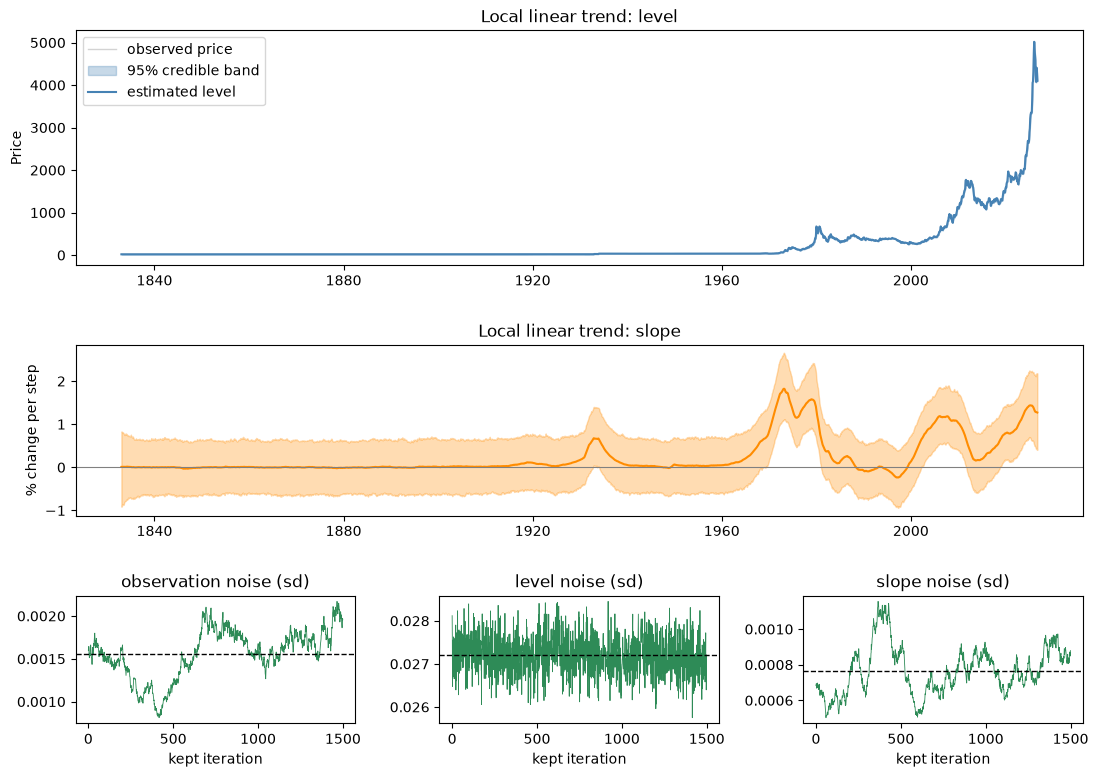

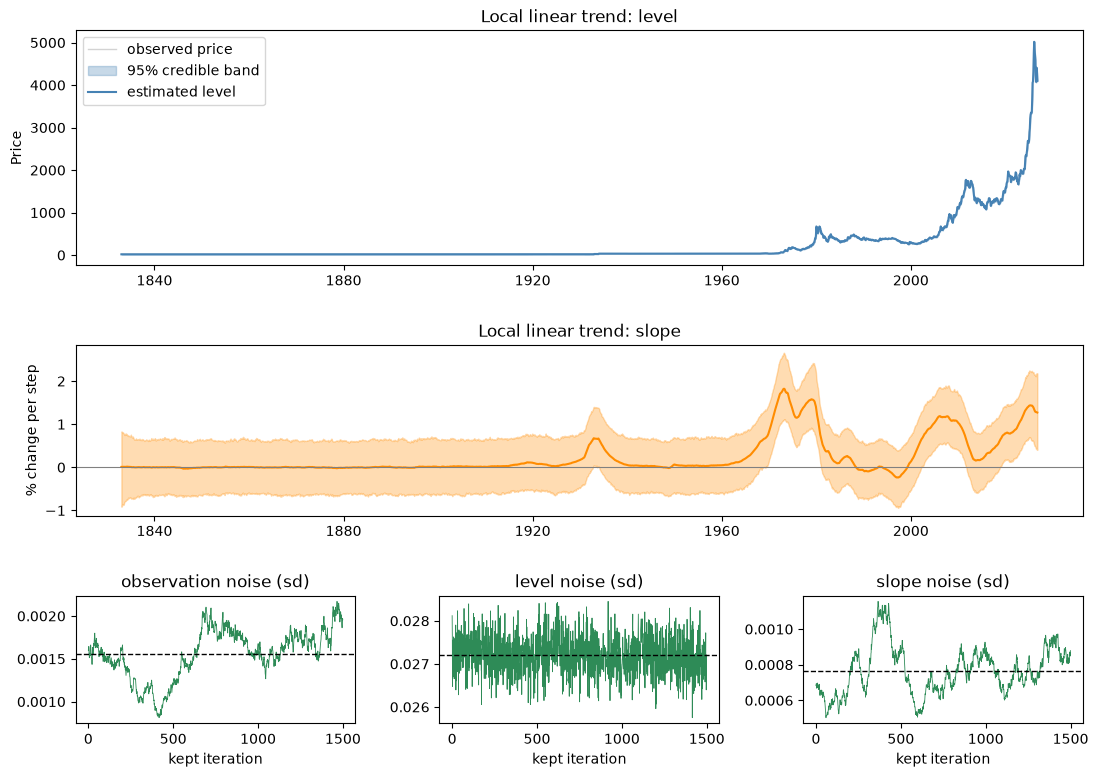

In [69]:
plot_bsts_llt(a)

In [26]:
def rmse(y_true,y_pred):
    assert len(y_true) == len(y_pred)
    return np.sqrt(np.mean(np.pow(y_true-y_pred,2)))

In [28]:
def mae(y_true,y_pred):
    assert len(y_true) == len(y_pred)
    return np.mean(np.abs(y_true-y_pred))